# Часть B. KNN Classification

датасет - Dry Bean Dataset, целевая переменная - `Class`.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from knn import KNN

SEED = 67

## Загрузка и исследование

In [10]:
beans_df = pd.read_excel("data/Dry_Bean_Dataset.xlsx")
print("Размер:", beans_df.shape)
beans_df.head()

Размер: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [11]:
print("Столбцы:", beans_df.columns.tolist())
print("Пропусков:", beans_df.isna().sum().sum())
print("Типы данных:")
beans_df.dtypes

Столбцы: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']
Пропусков: 0
Типы данных:


Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class                  str
dtype: object

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


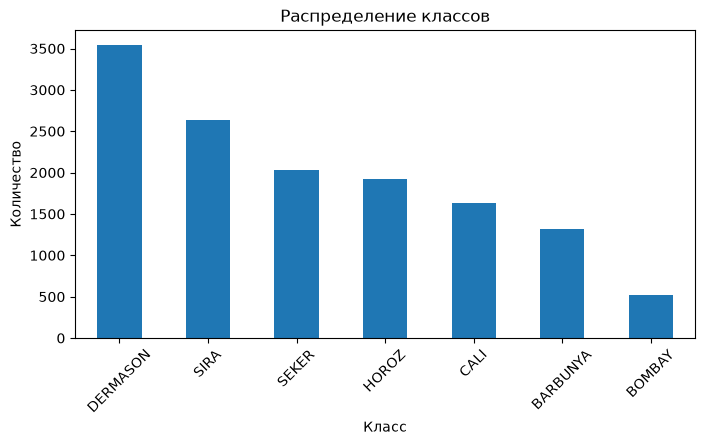

In [5]:
class_counts = beans_df["Class"].value_counts()
print(class_counts)

class_counts.plot(kind="bar", figsize=(8, 4))
plt.title("Распределение классов")
plt.xlabel("Класс")
plt.ylabel("Количество")
plt.xticks(rotation=45)
plt.show()

в датасете 13 611 объектов, 16 числовых признаков и 7 классов

пропусков нет

## X и y

In [12]:
X = beans_df.drop(columns="Class")
y = beans_df["Class"]

print("X:", X.shape)
print("y:", y.shape)

X: (13611, 16)
y: (13611,)


## Train / validation / test split

перемешиваем индексы с фиксированным seed и делим данные в отношении 60 / 20 / 20.

In [13]:
indices = np.random.default_rng(SEED).permutation(len(X))
train_end = int(0.6 * len(X))
val_end = int(0.8 * len(X))

train_idx = indices[:train_end]
val_idx = indices[train_end:val_end]
test_idx = indices[val_end:]

X_train = X.iloc[train_idx].reset_index(drop=True)
X_val = X.iloc[val_idx].reset_index(drop=True)
X_test = X.iloc[test_idx].reset_index(drop=True)

y_train = y.iloc[train_idx].reset_index(drop=True)
y_val = y.iloc[val_idx].reset_index(drop=True)
y_test = y.iloc[test_idx].reset_index(drop=True)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (8166, 16)
Validation: (2722, 16)
Test: (2723, 16)


## Scaling

сохраняем признаки без scaling и отдельно стандартизируем их

In [14]:
X_train_unscaled = X_train.copy()
X_val_unscaled = X_val.copy()
X_test_unscaled = X_test.copy()

means = X_train.mean()
stds = X_train.std().replace(0, 1)

X_train_scaled = (X_train - means) / stds
X_val_scaled = (X_val - means) / stds
X_test_scaled = (X_test - means) / stds

print("Без scaling:", X_train_unscaled.shape)
print("Со scaling:", X_train_scaled.shape)

Без scaling: (8166, 16)
Со scaling: (8166, 16)


## KNN

KNN не обучает веса

в `fit()` он только запоминает train-данные. Для нового объекта алгоритм считает расстояния до всех объектов train и выбирает $k$ ближайших соседей.

в классификации прогнозом становится самый частый класс среди соседей. В регрессии - среднее их целевых значений.

Евклидово расстояние:

$$d(x, z) = \sqrt{\sum_{j=1}^{m}(x_j-z_j)^2}$$

Манхэттенское расстояние:

$$d(x, z) = \sum_{j=1}^{m}|x_j-z_j|$$

scaling важен, потому что признак с большими значениями иначе будет сильнее влиять на расстояние.

## Проверка KNN

In [17]:
knn = KNN(k=5, task="classification", distance="euclidean")
knn.fit(X_train_scaled, y_train)

check_pred = knn.predict(X_val_scaled.iloc[:5])
pd.DataFrame({"true": y_val.iloc[:5], "prediction": check_pred})

,true,prediction
0,SIRA,DERMASON
1,BARBUNYA,BARBUNYA
2,HOROZ,HOROZ
3,SEKER,SEKER
4,DERMASON,DERMASON


## Метрики

Accuracy - доля правильных ответов. 

Macro F1 - среднее F1 по всем классам, поэтому каждый класс имеет одинаковый вес

In [18]:
def accuracy(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(y_true == y_pred)


def macro_f1(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    scores = []

    for class_name in np.unique(y_true):
        tp = np.sum((y_true == class_name) & (y_pred == class_name))
        fp = np.sum((y_true != class_name) & (y_pred == class_name))
        fn = np.sum((y_true == class_name) & (y_pred != class_name))

        precision = tp / (tp + fp) if tp + fp > 0 else 0
        recall = tp / (tp + fn) if tp + fn > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0
        scores.append(f1)

    return np.mean(scores)

## Сравнение на validation

проверяем несколько $k$, оба расстояния и признаки без scaling и со scaling.

In [20]:
k_values = [1, 3, 5, 6, 7, 8, 9, 15]

variants = [
    ("без scaling", "euclidean", X_train_unscaled, X_val_unscaled),
    ("без scaling", "manhattan", X_train_unscaled, X_val_unscaled),
    ("со scaling", "euclidean", X_train_scaled, X_val_scaled),
    ("со scaling", "manhattan", X_train_scaled, X_val_scaled),
]

results = []

for scaling, distance, X_train_part, X_val_part in variants:
    for k in k_values:
        model = KNN(k=k, task="classification", distance=distance)
        model.fit(X_train_part, y_train)
        y_pred = model.predict(X_val_part)

        results.append([
            scaling, distance, k,
            accuracy(y_val, y_pred),
            macro_f1(y_val, y_pred),
        ])

validation_results = pd.DataFrame(
    results,
    columns=["scaling", "distance", "k", "Accuracy", "Macro F1"],
)

validation_results.sort_values("Macro F1", ascending=False).round(4)

,scaling,distance,k,Accuracy,Macro F1
21,со scaling,euclidean,8,0.9258,0.9361
28,со scaling,manhattan,7,0.9258,0.9359
20,со scaling,euclidean,7,0.9258,0.9352
23,со scaling,euclidean,15,0.9262,0.9349
30,со scaling,manhattan,9,0.9240,0.9340
22,со scaling,euclidean,9,0.9229,0.9330
29,со scaling,manhattan,8,0.9217,0.9323
19,со scaling,euclidean,6,0.9217,0.9323
17,со scaling,euclidean,3,0.9225,0.9318
31,со scaling,manhattan,15,0.9221,0.9318


лучший результат на validation получился при `k = 8`, euclidean distance и scaling: accuracy $= 0.9258$, macro F1 $= 0.9361$. 

результат немного лучше, чем у manhattan с `k = 7`. 

Scaling **заметно** улучшает качество, потому что признаки имеют разные масштабы

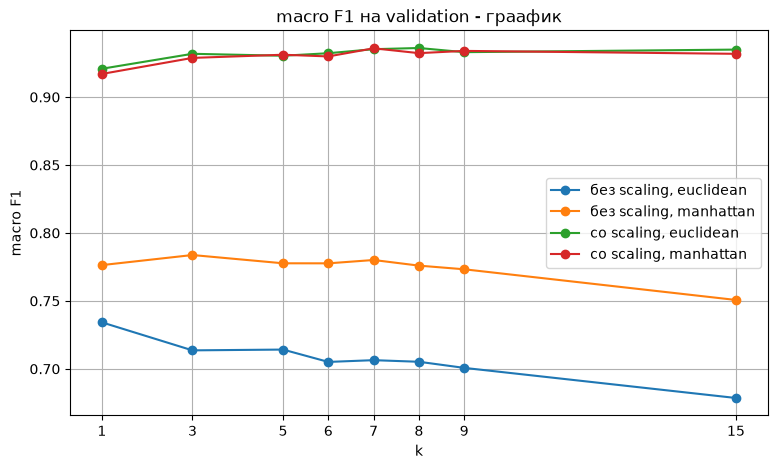

In [24]:
plt.figure(figsize=(9, 5))

for (scaling, distance), group in validation_results.groupby(["scaling", "distance"]):
    group = group.sort_values("k")
    plt.plot(group["k"], group["Macro F1"], marker="o", label=f"{scaling}, {distance}")

plt.title("macro F1 на validation - граафик")
plt.xlabel("k")
plt.ylabel("macro F1")
plt.xticks(k_values)
plt.legend()
plt.grid()
plt.show()

## Итоговая модель

параметры выбраны по validation. Теперь один раз оцениваем лучшую модель на test.

In [25]:
best_model = KNN(k=8, task="classification", distance="euclidean")
best_model.fit(X_train_scaled, y_train)

test_pred = best_model.predict(X_test_scaled)
test_accuracy = accuracy(y_test, test_pred)
test_macro_f1 = macro_f1(y_test, test_pred)

print(f"Accuracy: {test_accuracy:.4f}")
print(f"Macro F1: {test_macro_f1:.4f}")

Accuracy: 0.9251
Macro F1: 0.9359


## Confusion matrix

строки - настоящие классы, столбцы - предсказанные. Чем больше значений на главной диагонали, тем лучше модель.

In [26]:
classes = np.sort(y_test.unique())
class_indices = {class_name: i for i, class_name in enumerate(classes)}
confusion = np.zeros((len(classes), len(classes)), dtype=int)

for true_class, predicted_class in zip(y_test, test_pred):
    i = class_indices[true_class]
    j = class_indices[predicted_class]
    confusion[i, j] += 1

confusion_df = pd.DataFrame(confusion, index=classes, columns=classes)
confusion_df

,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
BARBUNYA,243,0,15,0,4,2,8
BOMBAY,0,121,0,0,0,0,0
CALI,9,0,312,0,5,0,2
DERMASON,0,0,0,644,1,6,29
HOROZ,1,0,4,2,357,0,13
SEKER,2,0,0,10,0,390,11
SIRA,2,0,2,61,6,9,452


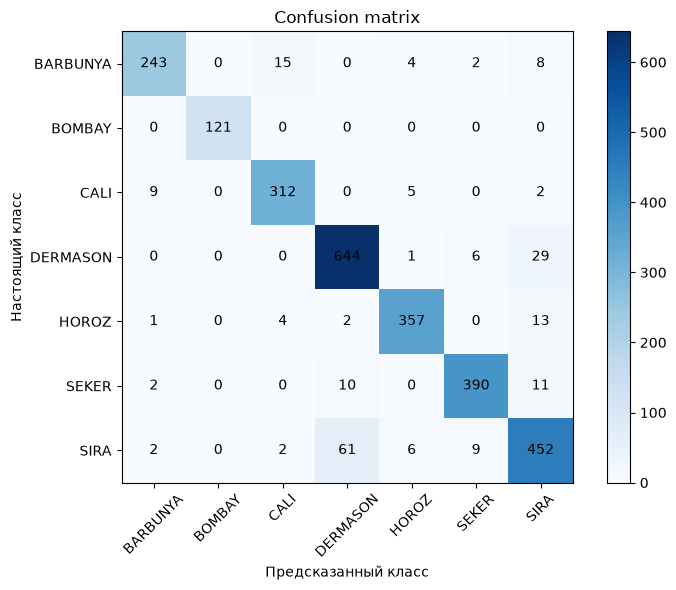

In [ ]:
plt.figure(figsize=(8, 6))
plt.imshow(confusion, cmap="Blues")
plt.colorbar()
plt.xticks(range(len(classes)), classes, rotation=45)
plt.yticks(range(len(classes)), classes)
plt.xlabel("Предсказанный класс")
plt.ylabel("Настоящий класс")
plt.title("Confusion matrix")

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(j, i, confusion[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

## Вывод

по validation выбрана модель с `k = 8`, Euclidean distance и scaling. На test получили Accuracy $= 0.9251$ и Macro F1 $= 0.9359$. Результат близок к validation, поэтому сильного переобучения не видно.

scaling заметно улучшил качество, так как признаки имеют разные масштабы. По confusion matrix модель чаще всего путает `SIRA` и `DERMASON`, а класс `BOMBAY` распознала без ошибок.